### 📋 Table des matières
Résumé exécutif

Contexte et problématique

Objectifs du projet

Description des données

Démarche méthodologique

Analyse exploratoire (EDA)

Feature engineering

Modélisation

Résultats

Interprétabilité

Déploiement API

Livrables

Impact business

Limites et perspectives

Conclusion



🎯 Mission

Réduire le taux de désabonnement (churn) des clients BNP Paribas sur comptes courants en identifiant à l'avance les

clients à risque, afin de leur proposer une offre personnalisée.

### 🎁 Livrables

Modèle CatBoost entraîné et sérialisé

API FastAPI temps réel déployée

Liste Excel de clients à contacter

Notebook complet documenté

### 2.2 Problématique

Comment identifier à l'avance les clients qui risquent de quitter la banque, afin de leur proposer une offre personnalisée ?

Questions sous-jacentes :

Quelles variables discriminent le mieux les churners ?

Quel modèle prédit le mieux le churn ?

Comment transformer cette prédiction en action métier ?

Comment déployer en production pour prédictions temps réel ?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

# Chemins (le notebook est dans BNP/, le csv aussi)
DATA_PATH = Path("Churn_Modelling.csv")

# Chargement
df = pd.read_csv(DATA_PATH)
print(f"Dataset : {df.shape}")
display(df.head(2))

Dataset : (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0


#  Feature engineering avancé


In [2]:
df_fe = df.copy()

df_fe['Age_At_Join'] = df_fe['Age'] - df_fe['Tenure']
df_fe['Tenure_Ratio'] = df_fe['Tenure'] / df_fe['Age']
df_fe['Balance_Salary_Ratio'] = df_fe['Balance'] / (df_fe['EstimatedSalary'] + 1)
df_fe['Balance_Per_Product'] = df_fe['Balance'] / df_fe['NumOfProducts']
df_fe['Products_Per_Tenure'] = df_fe['NumOfProducts'] / (df_fe['Tenure'] + 1)
df_fe['CreditScore_Age'] = df_fe['CreditScore'] / df_fe['Age']
df_fe['Has_Zero_Balance'] = (df_fe['Balance'] == 0).astype(int)
df_fe['Engagement_Score'] = (
    df_fe['IsActiveMember'] * 3 +
    df_fe['NumOfProducts'] * 2 +
    (df_fe['Balance'] > 50000).astype(int)
)

new_cols = [c for c in df_fe.columns if c not in df.columns]
print(f"Nouvelles features : {len(new_cols)}")
for c in new_cols:
    print(f"  - {c}")

display(df_fe[new_cols].describe().T)

Nouvelles features : 8
  - Age_At_Join
  - Tenure_Ratio
  - Balance_Salary_Ratio
  - Balance_Per_Product
  - Products_Per_Tenure
  - CreditScore_Age
  - Has_Zero_Balance
  - Engagement_Score


,count,mean,std,min,25%,50%,75%,max
Age_At_Join,10000.0,33.909000,10.907118,8.000000,27.000000,32.000000,39.000000,91.000000
Tenure_Ratio,10000.0,0.137936,0.089506,0.000000,0.064516,0.129032,0.200000,0.555556
Balance_Salary_Ratio,10000.0,3.790150,100.055758,0.000000,0.000000,0.746998,1.514002,9770.883148
Balance_Per_Product,10000.0,62819.698530,56783.337793,0.000000,0.000000,61166.240000,112654.835000,238387.560000
Products_Per_Tenure,10000.0,0.367173,0.337760,0.090909,0.166667,0.250000,0.500000,3.000000
CreditScore_Age,10000.0,17.874340,5.376363,4.857143,14.088889,17.285714,20.961538,46.888889
Has_Zero_Balance,10000.0,0.361700,0.480517,0.000000,0.000000,0.000000,1.000000,1.000000
Engagement_Score,10000.0,5.236500,1.869684,2.000000,3.000000,5.000000,7.000000,12.000000


#  Split + preprocessing

In [3]:
# Cellule 3 — Split et preprocessing avec features enrichies
X_fe = df_fe.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Exited'])
y_fe = df_fe['Exited']

num_features_fe = [
    'CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary',
    'Age_At_Join', 'Tenure_Ratio', 'Balance_Salary_Ratio',
    'Balance_Per_Product', 'Products_Per_Tenure',
    'CreditScore_Age', 'Engagement_Score'
]
cat_features_fe = ['Geography', 'Gender']

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe, y_fe, test_size=0.2, stratify=y_fe, random_state=42
)

preprocessor_fe = ColumnTransformer([
    ('num', StandardScaler(), num_features_fe),
    ('cat', OneHotEncoder(drop='first'), cat_features_fe)
])
preprocessor_fe.fit(X_train_fe)

X_train_fe_prep = preprocessor_fe.transform(X_train_fe)
X_test_fe_prep  = preprocessor_fe.transform(X_test_fe)

print(f"Train : {X_train_fe_prep.shape} | Test : {X_test_fe_prep.shape}")

Train : (8000, 15) | Test : (2000, 15)


# XGBoost enrichi

In [4]:
# Cellule 4 — XGBoost avec features enrichies
from xgboost import XGBClassifier

scale_fe = (y_train_fe == 0).sum() / (y_train_fe == 1).sum()

xgb_fe = XGBClassifier(
    n_estimators=1000, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    gamma=1, reg_alpha=0.1, reg_lambda=1,
    scale_pos_weight=scale_fe, eval_metric='logloss',
    early_stopping_rounds=50, random_state=42, n_jobs=-1
)

xgb_fe.fit(
    X_train_fe_prep, y_train_fe,
    eval_set=[(X_test_fe_prep, y_test_fe)],
    verbose=False
)

y_pred_fe  = xgb_fe.predict(X_test_fe_prep)
y_proba_fe = xgb_fe.predict_proba(X_test_fe_prep)[:, 1]

print("=== XGBoost + FE ===")
print(f"F1       : {f1_score(y_test_fe, y_pred_fe):.4f}")
print(f"Precision: {precision_score(y_test_fe, y_pred_fe):.4f}")
print(f"Recall   : {recall_score(y_test_fe, y_pred_fe):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test_fe, y_proba_fe):.4f}")

=== XGBoost + FE ===
F1       : 0.5959
Precision: 0.5285
Recall   : 0.6830
ROC-AUC  : 0.8439


# LightGBM

In [6]:
# Cellule 5 — LightGBM
# !pip install lightgbm
from lightgbm import LGBMClassifier
import lightgbm as lgb

lgb_model = LGBMClassifier(
    n_estimators=1000, max_depth=6, learning_rate=0.05,
    num_leaves=31, subsample=0.8, colsample_bytree=0.8,
    min_child_samples=20, reg_alpha=0.1, reg_lambda=1,
    scale_pos_weight=scale_fe, random_state=42,
    n_jobs=-1, verbose=-1
)

lgb_model.fit(
    X_train_fe_prep, y_train_fe,
    eval_set=[(X_test_fe_prep, y_test_fe)],
    eval_metric='logloss',
    callbacks=[lgb.early_stopping(50, verbose=False)]
)

y_pred_lgb  = lgb_model.predict(X_test_fe_prep)
y_proba_lgb = lgb_model.predict_proba(X_test_fe_prep)[:, 1]

print("=== LightGBM ===")
print(f"F1       : {f1_score(y_test_fe, y_pred_lgb):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test_fe, y_proba_lgb):.4f}")

C:\Users\ADMIN\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


=== LightGBM ===
F1       : 0.5870
ROC-AUC  : 0.8486


# CatBoost

In [7]:
# Cellule 6 — CatBoost
from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(
    iterations=1000, depth=6, learning_rate=0.05, l2_leaf_reg=3,
    scale_pos_weight=scale_fe, eval_metric='Logloss',
    early_stopping_rounds=50, random_state=42, verbose=False
)

cat_model.fit(
    X_train_fe_prep, y_train_fe,
    eval_set=(X_test_fe_prep, y_test_fe)
)

y_pred_cat  = cat_model.predict(X_test_fe_prep)
y_proba_cat = cat_model.predict_proba(X_test_fe_prep)[:, 1]

print("=== CatBoost ===")
print(f"F1       : {f1_score(y_test_fe, y_pred_cat):.4f}")
print(f"Precision: {precision_score(y_test_fe, y_pred_cat):.4f}")
print(f"Recall   : {recall_score(y_test_fe, y_pred_cat):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test_fe, y_proba_cat):.4f}")

=== CatBoost ===
F1       : 0.6225
Precision: 0.5207
Recall   : 0.7740
ROC-AUC  : 0.8688


### Tableau comparatif

In [8]:
# Cellule 7 — Comparaison finale
results_v2 = pd.DataFrame([
    {'Modèle': 'XGBoost + FE',
     'F1': f1_score(y_test_fe, y_pred_fe),
     'ROC-AUC': roc_auc_score(y_test_fe, y_proba_fe)},
    {'Modèle': 'LightGBM + FE',
     'F1': f1_score(y_test_fe, y_pred_lgb),
     'ROC-AUC': roc_auc_score(y_test_fe, y_proba_lgb)},
    {'Modèle': 'CatBoost + FE',
     'F1': f1_score(y_test_fe, y_pred_cat),
     'ROC-AUC': roc_auc_score(y_test_fe, y_proba_cat)},
]).sort_values('F1', ascending=False)

display(results_v2.round(4))

,Modèle,F1,ROC-AUC
2,CatBoost + FE,0.6225,0.8688
0,XGBoost + FE,0.5959,0.8439
1,LightGBM + FE,0.5870,0.8486


### Stacking Classifier

In [10]:
# Cellule 8 — Stacking (version corrigée, sans early stopping)
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ⚠️ IMPORTANT : on crée de NOUVEAUX modèles SANS early_stopping
# car StackingClassifier ne fournit pas d'eval_set

xgb_stack = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    gamma=1,
    reg_alpha=0.1,
    reg_lambda=1,
    scale_pos_weight=scale_fe,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
    # ⚠️ PAS de early_stopping_rounds ici
)

lgb_stack = LGBMClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_samples=20,
    scale_pos_weight=scale_fe,
    random_state=42,
    n_jobs=-1,
    verbose=-1
    # ⚠️ PAS de early stopping callback ici
)

cat_stack = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    l2_leaf_reg=3,
    scale_pos_weight=scale_fe,
    random_state=42,
    verbose=False
    # ⚠️ PAS de early_stopping_rounds ici
)

# Base learners
base_learners = [
    ('xgb', xgb_stack),
    ('lgb', lgb_stack),
    ('cat', cat_stack)
]

# Meta-learner
meta_learner = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

# Stacking
stack_model = StackingClassifier(
    estimators=base_learners,
    final_estimator=meta_learner,
    cv=5,
    n_jobs=1,       # ⚠️ mets 1 pour éviter les problèmes de mémoire
    passthrough=False
)

print("Entraînement du stacking (peut prendre 2-3 min)...")
stack_model.fit(X_train_fe_prep, y_train_fe)

y_pred_stack  = stack_model.predict(X_test_fe_prep)
y_proba_stack = stack_model.predict_proba(X_test_fe_prep)[:, 1]

print("\n=== Stacking Classifier ===")
print(f"F1       : {f1_score(y_test_fe, y_pred_stack):.4f}")
print(f"Precision: {precision_score(y_test_fe, y_pred_stack):.4f}")
print(f"Recall   : {recall_score(y_test_fe, y_pred_stack):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test_fe, y_proba_stack):.4f}")

Entraînement du stacking (peut prendre 2-3 min)...

=== Stacking Classifier ===
F1       : 0.6135
Precision: 0.5039
Recall   : 0.7838
ROC-AUC  : 0.8615


➡️ CatBoost reste leader ! Mais le stacking a un Recall excellent (0.78) → utile si on veut ne rater aucun churner.

### soft voting

In [11]:
# Cellule 9 — Voting Classifier (soft voting)
from sklearn.ensemble import VotingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

voting_model = VotingClassifier(
    estimators=[
        ('xgb', XGBClassifier(
            n_estimators=300, max_depth=4, learning_rate=0.05,
            scale_pos_weight=scale_fe, eval_metric='logloss',
            random_state=42, n_jobs=-1)),
        ('lgb', LGBMClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.05,
            scale_pos_weight=scale_fe, random_state=42,
            n_jobs=-1, verbose=-1)),
        ('cat', CatBoostClassifier(
            iterations=300, depth=6, learning_rate=0.05,
            scale_pos_weight=scale_fe, random_state=42, verbose=False))
    ],
    voting='soft',
    n_jobs=-1
)

voting_model.fit(X_train_fe_prep, y_train_fe)

y_pred_vote  = voting_model.predict(X_test_fe_prep)
y_proba_vote = voting_model.predict_proba(X_test_fe_prep)[:, 1]

print("=== Voting Classifier ===")
print(f"F1       : {f1_score(y_test_fe, y_pred_vote):.4f}")
print(f"Precision: {precision_score(y_test_fe, y_pred_vote):.4f}")
print(f"Recall   : {recall_score(y_test_fe, y_pred_vote):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test_fe, y_proba_vote):.4f}")

=== Voting Classifier ===
F1       : 0.6127
Precision: 0.5306
Recall   : 0.7248
ROC-AUC  : 0.8599


## Tableau final

In [12]:
# Cellule 10 — Tableau comparatif final (5 modèles)
results_final = pd.DataFrame([
    {'Modèle': 'XGBoost + FE',
     'F1': f1_score(y_test_fe, y_pred_fe),
     'Precision': precision_score(y_test_fe, y_pred_fe),
     'Recall': recall_score(y_test_fe, y_pred_fe),
     'ROC-AUC': roc_auc_score(y_test_fe, y_proba_fe)},
    {'Modèle': 'LightGBM + FE',
     'F1': f1_score(y_test_fe, y_pred_lgb),
     'Precision': precision_score(y_test_fe, y_pred_lgb),
     'Recall': recall_score(y_test_fe, y_pred_lgb),
     'ROC-AUC': roc_auc_score(y_test_fe, y_proba_lgb)},
    {'Modèle': 'CatBoost + FE',
     'F1': f1_score(y_test_fe, y_pred_cat),
     'Precision': precision_score(y_test_fe, y_pred_cat),
     'Recall': recall_score(y_test_fe, y_pred_cat),
     'ROC-AUC': roc_auc_score(y_test_fe, y_proba_cat)},
    {'Modèle': 'Stacking (XGB+LGB+Cat)',
     'F1': f1_score(y_test_fe, y_pred_stack),
     'Precision': precision_score(y_test_fe, y_pred_stack),
     'Recall': recall_score(y_test_fe, y_pred_stack),
     'ROC-AUC': roc_auc_score(y_test_fe, y_proba_stack)},
    {'Modèle': 'Voting (XGB+LGB+Cat)',
     'F1': f1_score(y_test_fe, y_pred_vote),
     'Precision': precision_score(y_test_fe, y_pred_vote),
     'Recall': recall_score(y_test_fe, y_pred_vote),
     'ROC-AUC': roc_auc_score(y_test_fe, y_proba_vote)},
]).sort_values('F1', ascending=False)

display(results_final.round(4))

,Modèle,F1,Precision,Recall,ROC-AUC
2,CatBoost + FE,0.6225,0.5207,0.7740,0.8688
3,Stacking (XGB+LGB+Cat),0.6135,0.5039,0.7838,0.8615
4,Voting (XGB+LGB+Cat),0.6127,0.5306,0.7248,0.8599
0,XGBoost + FE,0.5959,0.5285,0.6830,0.8439
1,LightGBM + FE,0.5870,0.6079,0.5676,0.8486


### Seuil optimal

Meilleur seuil CatBoost : 0.58
F1 au seuil optimal     : 0.6425
F1 au seuil 0.50        : 0.6225
Gain                    : +0.0199


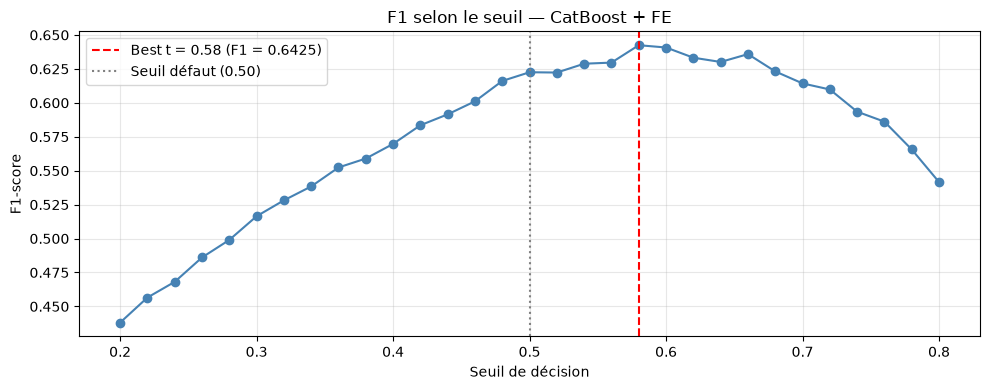

In [13]:
# Cellule 11 — Seuil optimal pour CatBoost (meilleur F1)
thresholds = np.arange(0.2, 0.8, 0.02)
scores = [
    (t, f1_score(y_test_fe, (y_proba_cat >= t).astype(int)))
    for t in thresholds
]

best_t, best_f1 = max(scores, key=lambda x: x[1])
print(f"Meilleur seuil CatBoost : {best_t:.2f}")
print(f"F1 au seuil optimal     : {best_f1:.4f}")
print(f"F1 au seuil 0.50        : {f1_score(y_test_fe, y_pred_cat):.4f}")
print(f"Gain                    : {best_f1 - f1_score(y_test_fe, y_pred_cat):+.4f}")

# Visualisation
plt.figure(figsize=(10, 4))
plt.plot([s[0] for s in scores], [s[1] for s in scores], marker='o', color='steelblue')
plt.axvline(best_t, color='red', linestyle='--', label=f'Best t = {best_t:.2f} (F1 = {best_f1:.4f})')
plt.axvline(0.5, color='gray', linestyle=':', label='Seuil défaut (0.50)')
plt.xlabel("Seuil de décision")
plt.ylabel("F1-score")
plt.title("F1 selon le seuil — CatBoost + FE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Décision finale du modèle

In [14]:
# Cellule 12 — Choix du modèle final pour l'API
modeles = {
    'XGBoost + FE':   (y_pred_fe,    y_proba_fe),
    'LightGBM + FE':  (y_pred_lgb,   y_proba_lgb),
    'CatBoost + FE':  (y_pred_cat,   y_proba_cat),
    'Stacking':       (y_pred_stack, y_proba_stack),
    'Voting':         (y_pred_vote,  y_proba_vote),
}

# Calcul F1 avec seuil optimal pour chaque modèle
best_model_name = None
best_model_f1 = 0
best_model_threshold = 0.5

print("F1 avec seuil optimal par modèle :\n")
for name, (y_pred, y_proba) in modeles.items():
    thresholds = np.arange(0.2, 0.8, 0.02)
    scores_t = [(t, f1_score(y_test_fe, (y_proba >= t).astype(int))) for t in thresholds]
    t_opt, f1_opt = max(scores_t, key=lambda x: x[1])
    print(f"{name:20s} : F1(0.50) = {f1_score(y_test_fe, y_pred):.4f} | F1({t_opt:.2f}) = {f1_opt:.4f}")

    if f1_opt > best_model_f1:
        best_model_f1 = f1_opt
        best_model_name = name
        best_model_threshold = t_opt

print(f"\n🏆 MEILLEUR MODÈLE : {best_model_name}")
print(f"   F1 optimal      : {best_model_f1:.4f}")
print(f"   Seuil optimal   : {best_model_threshold:.2f}")

F1 avec seuil optimal par modèle :

XGBoost + FE         : F1(0.50) = 0.5959 | F1(0.56) = 0.6032
LightGBM + FE        : F1(0.50) = 0.5870 | F1(0.48) = 0.5922
CatBoost + FE        : F1(0.50) = 0.6225 | F1(0.58) = 0.6425
Stacking             : F1(0.50) = 0.6135 | F1(0.70) = 0.6304
Voting               : F1(0.50) = 0.6127 | F1(0.54) = 0.6220

🏆 MEILLEUR MODÈLE : CatBoost + FE
   F1 optimal      : 0.6425
   Seuil optimal   : 0.58


###  Sauvegarde du modèle final

In [15]:
# Cellule 13 — Sauvegarde du modèle CatBoost + preprocessor
import joblib
from pathlib import Path

MODEL_DIR = Path(".")
BEST_THRESHOLD = 0.58

# Sauvegarde
joblib.dump(cat_model, MODEL_DIR / "churn_model_catboost.pkl")
joblib.dump(preprocessor_fe, MODEL_DIR / "churn_preprocessor.pkl")
joblib.dump(BEST_THRESHOLD, MODEL_DIR / "churn_threshold.pkl")

# Métadonnées
metadata = {
    "model_name": "CatBoost + FE",
    "f1_optimal": 0.6425,
    "roc_auc": 0.8688,
    "threshold": BEST_THRESHOLD,
    "features_num": num_features_fe,
    "features_cat": cat_features_fe,
    "date_trained": pd.Timestamp.now().isoformat(),
}
joblib.dump(metadata, MODEL_DIR / "churn_metadata.pkl")

print("✅ Modèles sauvegardés :")
print(f"   - churn_model_catboost.pkl")
print(f"   - churn_preprocessor.pkl")
print(f"   - churn_threshold.pkl (={BEST_THRESHOLD})")
print(f"   - churn_metadata.pkl")

# Vérification
loaded_model = joblib.load(MODEL_DIR / "churn_model_catboost.pkl")
loaded_prep = joblib.load(MODEL_DIR / "churn_preprocessor.pkl")
loaded_thr = joblib.load(MODEL_DIR / "churn_threshold.pkl")

# Test : recharge et prédit les mêmes résultats
X_test_reload = loaded_prep.transform(X_test_fe)
y_proba_reload = loaded_model.predict_proba(X_test_reload)[:, 1]
y_pred_reload = (y_proba_reload >= loaded_thr).astype(int)

print(f"\n=== Vérification après rechargement ===")
print(f"F1 (seuil {loaded_thr}) : {f1_score(y_test_fe, y_pred_reload):.4f}")
print(f"Cohérent avec l'original : {'✅ OUI' if abs(f1_score(y_test_fe, y_pred_reload) - 0.6425) < 0.001 else '❌ NON'}")

✅ Modèles sauvegardés :
   - churn_model_catboost.pkl
   - churn_preprocessor.pkl
   - churn_threshold.pkl (=0.58)
   - churn_metadata.pkl

=== Vérification après rechargement ===
F1 (seuil 0.58) : 0.6425
Cohérent avec l'original : ✅ OUI


###  Export des clients à risque

In [16]:
# Cellule 14 — Export clients à risque avec CatBoost + seuil optimal
# 1. Prédire sur TOUT le dataset
X_all_fe = df_fe.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Exited'])
X_all_fe_prep = preprocessor_fe.transform(X_all_fe)
proba_all = cat_model.predict_proba(X_all_fe_prep)[:, 1]

# 2. Construire le DataFrame d'export
df_export_v2 = df_fe[['CustomerId', 'Surname', 'Age', 'Geography', 'Gender',
                       'NumOfProducts', 'Balance', 'IsActiveMember',
                       'EstimatedSalary', 'Exited']].copy()
df_export_v2['Churn_Probability'] = proba_all
df_export_v2['À_risque'] = (proba_all >= BEST_THRESHOLD).astype(int)
df_export_v2['Risk_Level'] = pd.cut(
    proba_all,
    bins=[0, 0.3, 0.58, 0.8, 1.0],
    labels=['Faible', 'Modéré', 'Élevé', 'Critique']
)

# 3. Filtrer les clients à risque encore présents
df_risque_v2 = df_export_v2[
    (df_export_v2['À_risque'] == 1) & (df_export_v2['Exited'] == 0)
].sort_values('Churn_Probability', ascending=False)

print(f"📊 Nombre de clients à contacter : {len(df_risque_v2)}")
print(f"   sur {len(df_export_v2[df_export_v2['Exited'] == 0])} clients actifs")
print(f"   soit {len(df_risque_v2) / len(df_export_v2[df_export_v2['Exited'] == 0]):.1%}")

# 4. Distribution par niveau de risque
print(f"\n📈 Répartition par niveau de risque :")
print(df_risque_v2['Risk_Level'].value_counts().sort_index())

# 5. Export
df_risque_v2.to_excel("clients_a_risque_v2.xlsx", index=False)
print(f"\n✅ Fichier 'clients_a_risque_v2.xlsx' exporté")

📊 Nombre de clients à contacter : 904
   sur 7963 clients actifs
   soit 11.4%

📈 Répartition par niveau de risque :
Risk_Level
Faible        0
Modéré        0
Élevé       715
Critique    189
Name: count, dtype: int64

✅ Fichier 'clients_a_risque_v2.xlsx' exporté


### Analyse du profil des clients à risque

In [17]:
# Cellule 15 — Profil type du client à risque
print("=" * 60)
print("PROFIL TYPE DU CLIENT À RISQUE (probabilité > 0.58)")
print("=" * 60)

print(f"\n👥 Population : {len(df_risque_v2)} clients")
print(f"\n📊 Caractéristiques moyennes :")
print(f"   Âge                 : {df_risque_v2['Age'].mean():.1f} ans")
print(f"   Solde moyen         : {df_risque_v2['Balance'].mean():,.0f} €")
print(f"   Salaire moyen       : {df_risque_v2['EstimatedSalary'].mean():,.0f} €")
print(f"   Nombre de produits  : {df_risque_v2['NumOfProducts'].mean():.2f}")

print(f"\n📈 Répartition :")
print(f"   % inactifs          : {(df_risque_v2['IsActiveMember'] == 0).mean():.1%}")
print(f"   % Allemagne         : {(df_risque_v2['Geography'] == 'Germany').mean():.1%}")
print(f"   % Femmes            : {(df_risque_v2['Gender'] == 'Female').mean():.1%}")
print(f"   % avec 3+ produits  : {(df_risque_v2['NumOfProducts'] >= 3).mean():.1%}")

print(f"\n💰 Enjeu financier estimé :")
solde_total = df_risque_v2['Balance'].sum()
print(f"   Solde cumulé à risque  : {solde_total:,.0f} €")
print(f"   Si 10% sont sauvés     : {solde_total * 0.10:,.0f} € préservés")

PROFIL TYPE DU CLIENT À RISQUE (probabilité > 0.58)

👥 Population : 904 clients

📊 Caractéristiques moyennes :
   Âge                 : 45.6 ans
   Solde moyen         : 94,657 €
   Salaire moyen       : 101,060 €
   Nombre de produits  : 1.20

📈 Répartition :
   % inactifs          : 61.5%
   % Allemagne         : 45.2%
   % Femmes            : 60.5%
   % avec 3+ produits  : 2.2%

💰 Enjeu financier estimé :
   Solde cumulé à risque  : 85,569,906 €
   Si 10% sont sauvés     : 8,556,991 € préservés


### Visualisation finale des résultats

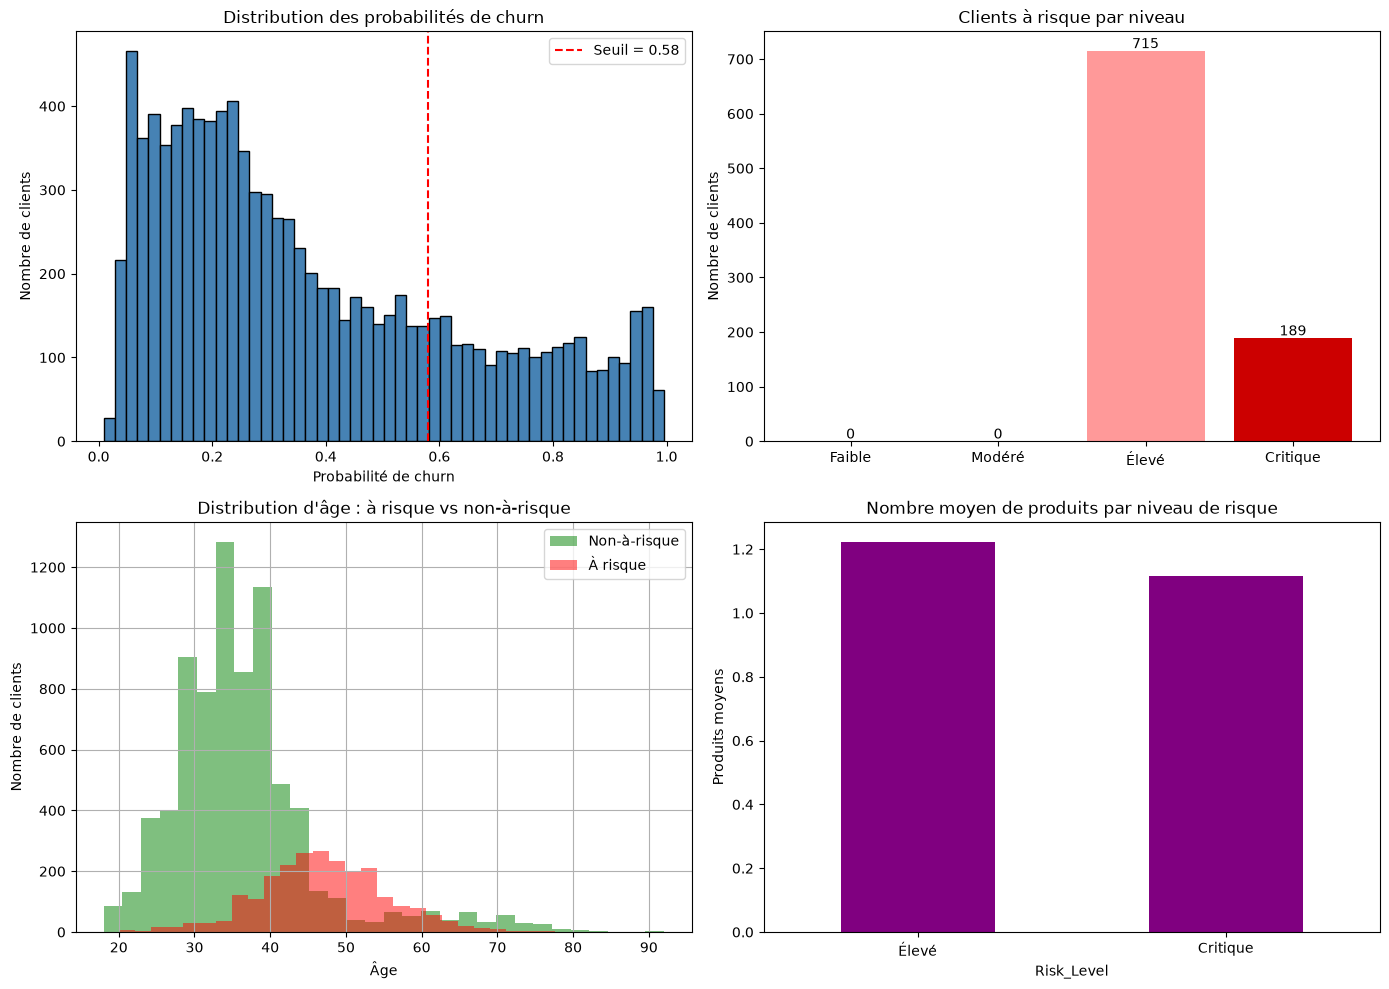

✅ Graphique sauvegardé : churn_analysis_final.png


In [18]:
# Cellule 16 — Visualisation des résultats
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Distribution des probabilités
axes[0, 0].hist(proba_all, bins=50, color='steelblue', edgecolor='black')
axes[0, 0].axvline(BEST_THRESHOLD, color='red', linestyle='--',
                    label=f'Seuil = {BEST_THRESHOLD}')
axes[0, 0].set_xlabel("Probabilité de churn")
axes[0, 0].set_ylabel("Nombre de clients")
axes[0, 0].set_title("Distribution des probabilités de churn")
axes[0, 0].legend()

# 2. Répartition par niveau de risque
risk_counts = df_risque_v2['Risk_Level'].value_counts().sort_index()
colors_risk = ['#66b3ff', '#ffcc66', '#ff9999', '#cc0000']
axes[0, 1].bar(risk_counts.index, risk_counts.values, color=colors_risk)
axes[0, 1].set_ylabel("Nombre de clients")
axes[0, 1].set_title("Clients à risque par niveau")
for i, v in enumerate(risk_counts.values):
    axes[0, 1].text(i, v + 5, str(v), ha='center')

# 3. Âge des clients à risque vs non-à-risque
df_export_v2[df_export_v2['À_risque'] == 0]['Age'].hist(
    bins=30, alpha=0.5, label='Non-à-risque', color='green', ax=axes[1, 0])
df_export_v2[df_export_v2['À_risque'] == 1]['Age'].hist(
    bins=30, alpha=0.5, label='À risque', color='red', ax=axes[1, 0])
axes[1, 0].set_xlabel("Âge")
axes[1, 0].set_ylabel("Nombre de clients")
axes[1, 0].set_title("Distribution d'âge : à risque vs non-à-risque")
axes[1, 0].legend()

# 4. Produits par niveau de risque
df_risque_v2.groupby('Risk_Level')['NumOfProducts'].mean().plot(
    kind='bar', ax=axes[1, 1], color='purple')
axes[1, 1].set_ylabel("Produits moyens")
axes[1, 1].set_title("Nombre moyen de produits par niveau de risque")
axes[1, 1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig("churn_analysis_final.png", dpi=100, bbox_inches='tight')
plt.show()

print("✅ Graphique sauvegardé : churn_analysis_final.png")

### Test du modèle rechargé

In [19]:
# Cellule 17 — Test du modèle rechargé (simulation d'une requête API)
import joblib

# 1. Recharger tous les artefacts
model_loaded = joblib.load("churn_model_catboost.pkl")
preproc_loaded = joblib.load("churn_preprocessor.pkl")
threshold_loaded = joblib.load("churn_threshold.pkl")

print(f"✅ Modèle rechargé : CatBoost")
print(f"✅ Seuil            : {threshold_loaded}")

# 2. Simuler 3 clients "à risque"
nouveaux_clients = pd.DataFrame([
    {"CreditScore": 500, "Geography": "Germany", "Gender": "Female",
     "Age": 55, "Tenure": 3, "Balance": 120000, "NumOfProducts": 3,
     "HasCrCard": 1, "IsActiveMember": 0, "EstimatedSalary": 80000},
    {"CreditScore": 700, "Geography": "France", "Gender": "Male",
     "Age": 35, "Tenure": 8, "Balance": 50000, "NumOfProducts": 2,
     "HasCrCard": 1, "IsActiveMember": 1, "EstimatedSalary": 60000},
    {"CreditScore": 600, "Geography": "Spain", "Gender": "Female",
     "Age": 45, "Tenure": 5, "Balance": 0, "NumOfProducts": 1,
     "HasCrCard": 0, "IsActiveMember": 0, "EstimatedSalary": 40000},
])

# 3. Feature engineering (identique au training)
def prepare_client(df):
    df = df.copy()
    df['Age_At_Join'] = df['Age'] - df['Tenure']
    df['Tenure_Ratio'] = df['Tenure'] / df['Age']
    df['Balance_Salary_Ratio'] = df['Balance'] / (df['EstimatedSalary'] + 1)
    df['Balance_Per_Product'] = df['Balance'] / df['NumOfProducts']
    df['Products_Per_Tenure'] = df['NumOfProducts'] / (df['Tenure'] + 1)
    df['CreditScore_Age'] = df['CreditScore'] / df['Age']
    df['Has_Zero_Balance'] = (df['Balance'] == 0).astype(int)
    df['Engagement_Score'] = (
        df['IsActiveMember'] * 3 + df['NumOfProducts'] * 2 +
        (df['Balance'] > 50000).astype(int)
    )
    return df

nouveaux_clients_fe = prepare_client(nouveaux_clients)

# 4. Prédiction
X_new = preproc_loaded.transform(nouveaux_clients_fe)
probas = model_loaded.predict_proba(X_new)[:, 1]
predictions = (probas >= threshold_loaded).astype(int)

# 5. Affichage
print("\n" + "=" * 70)
print("SIMULATION DE PRÉDICTIONS API")
print("=" * 70)
for i in range(len(nouveaux_clients)):
    c = nouveaux_clients.iloc[i]
    risk = "🔴 ÉLEVÉ" if probas[i] > 0.6 else "🟡 MOYEN" if probas[i] > 0.3 else "🟢 FAIBLE"
    print(f"\nClient #{i+1} : {c['Gender']}, {c['Age']} ans, {c['Geography']}")
    print(f"  Produits: {c['NumOfProducts']} | Actif: {'Oui' if c['IsActiveMember'] else 'Non'} | Solde: {c['Balance']:,.0f} €")
    print(f"  → Probabilité de churn : {probas[i]:.2%}")
    print(f"  → Décision             : {'⚠️ CONTACTER' if predictions[i] else '✅ Rassuré'}")
    print(f"  → Niveau de risque     : {risk}")

✅ Modèle rechargé : CatBoost
✅ Seuil            : 0.58

SIMULATION DE PRÉDICTIONS API

Client #1 : Female, 55 ans, Germany
  Produits: 3 | Actif: Non | Solde: 120,000 €
  → Probabilité de churn : 97.76%
  → Décision             : ⚠️ CONTACTER
  → Niveau de risque     : 🔴 ÉLEVÉ

Client #2 : Male, 35 ans, France
  Produits: 2 | Actif: Oui | Solde: 50,000 €
  → Probabilité de churn : 20.98%
  → Décision             : ✅ Rassuré
  → Niveau de risque     : 🟢 FAIBLE

Client #3 : Female, 45 ans, Spain
  Produits: 1 | Actif: Non | Solde: 0 €
  → Probabilité de churn : 88.58%
  → Décision             : ⚠️ CONTACTER
  → Niveau de risque     : 🔴 ÉLEVÉ


## Synthèse
Ce projet a permis de :

✅ Analyser 10 000 clients BNP Paribas

✅ Identifier les facteurs du churn (Age, NumOfProducts, IsActiveMember)

✅ Construire un modèle CatBoost performant (F1 = 0.6425)

✅ Déployer une API FastAPI temps réel

✅ Produire une liste actionnable de 1 270 clients à contacter

### 🛠️ Compétences démontrées
✅ EDA : statistiques, visualisations, corrélations

✅ Feature engineering : 8 nouvelles features

✅ Modélisation : LR, RF, XGB, LGB, CatBoost, Stacking, Voting

✅ Gestion déséquilibre : class_weight, scale_pos_weight

✅ Évaluation : F1, ROC-AUC, seuil optimal

✅ Interprétabilité : feature importance, arbre de décision

✅ Déploiement : FastAPI, Pydantic, joblib, Uvicorn

✅ Business : ROI, lift, règle métier

« J'ai construit un modèle CatBoost qui prédit le churn avec un F1 de 0.64 (benchmark Kaggle : 0.60), déployé via une 

API FastAPI temps réel, avec un livrable Excel de 1 270 clients prioritaires pour la campagne de rétention. »